# Ticket number and model residuals

Does the ticket number explain survival that the other features cannot?

**1. Model without the ticket.** Logistic regression on every feature except the ticket: class, sex, title, age (median-filled, with a flag), SibSp, Parch, fare (log), port and deck. Deck comes from the passenger's own cabin only, not from ticket-mates, so no ticket information enters.

**2. Held-out residuals.** 10-fold cross-validation, repeated 10 times with different shuffles. Each train passenger gets 10 predictions, each from a model that never saw them, and these are averaged. The residual is survived (1 or 0) minus that prediction: positive means the passenger did better than the model expected.

**3. Ticket groupings, prefix ignored.** Only the number is used, so `PC 17474` and `17474` count as the same number, and `STON/O2. 3101294` and `SOTON/O.Q. 3101295` as consecutive:

- **Exact ticket**: passengers holding the same ticket (prefix included), for comparison.
- **Consecutive run**: tickets whose numbers follow on with gaps of at most 1 (or at most 3) are chained into one run.
- **Hundreds**: the number with its last two digits dropped (`3470xx`, `175xx`).
- **Window**: the first 3 digits for numbers of 6 or more digits, otherwise the first 2 (`347xxx`, `17xxx`).
- **Band**: length of the number and its first digit (`3xxxxx`).
- **Prefix**: the ticket type (`PC`, `C.A.`, Number only), for comparison.

**4. Families.** Passengers who share a ticket or a family (`FamilyId` from `families_v3.ipynb`) are linked into **parties**. A ticket grouping that only reflects a party sharing one fate is a party effect, not a ticket-number effect. Each test is therefore run twice: over passengers, and over parties, with each party counted once.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "font.family": ["Helvetica Neue", "Arial", "DejaVu Sans"], "font.size": 9.5,
    "text.color": INK, "axes.edgecolor": AXIS, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.facecolor": SURFACE, "figure.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110,
})
RNG = np.random.default_rng(0)
PERMS = 4000

def find_data():
    from pathlib import Path
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "data" / "complete_data.csv").exists():
            return p / "data" / "complete_data.csv"
c = pd.read_csv(find_data())

# ---- non-ticket features
t = c["Name"].str.extract(r",\s*([^.]+)\.")[0].str.strip()
t = t.replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
c["Title"] = t.where(t.isin(["Mr", "Mrs", "Miss", "Master"]), "Rare")
c["OwnDeck"] = c["Cabin"].str[0].fillna("None").replace({"T": "A", "G": "F"})
c["LogFare"] = np.log1p(c["Fare"])
c["AgeMissing"] = c["Age"].isna().astype(int)
c["PclassS"] = c["Pclass"].astype(str)
c["Embarked"] = c["Embarked"].fillna("S")
CAT = ["PclassS", "Sex", "Title", "Embarked", "OwnDeck"]
NUM = ["Age", "AgeMissing", "SibSp", "Parch", "LogFare"]

# ---- ticket groupings, prefix ignored
def raw_prefix(x):
    parts = x.split(" ")
    if x.replace(" ", "").isdigit():
        return ""
    return " ".join(parts[:-1]) if parts[-1].isdigit() else x
c["Prefix"] = c["Ticket"].map(lambda x: "Number only" if raw_prefix(x) == "" else re.sub(r"[./ ]", "", raw_prefix(x)).upper())
c["Num"] = pd.to_numeric(c["Ticket"].str.extract(r"(\d+)$")[0])
s = c["Num"].map(lambda v: "" if pd.isna(v) else str(int(v)))
dig = s.str.len()
c["Band"] = np.where(dig > 0, s.str[:1] + dig.map(lambda d: "x" * max(d - 1, 0)), np.nan)
k = np.where(dig >= 6, 3, np.where(dig >= 4, 2, 1))
c["Window"] = [np.nan if d == 0 else v[:kk] + "x" * (d - kk) for v, d, kk in zip(s, dig, k)]
c["Hundreds"] = [np.nan if d == 0 else (v[:-2] + "xx" if d >= 4 else v[:1] + "x" * (d - 1)) for v, d in zip(s, dig)]

def runs(gap):
    u = np.sort(c["Num"].dropna().unique())
    rid = np.concatenate([[0], np.cumsum(np.diff(u) > gap)])
    first = pd.Series(u).groupby(rid).transform("min").astype(int).astype(str).values
    last = pd.Series(u).groupby(rid).transform("max").astype(int).astype(str).values
    lab = dict(zip(u, [f if f == l else f"{f}-{l[-3:] if len(l) > 3 else l}" for f, l in zip(first, last)]))
    return c["Num"].map(lab)
c["Run1"] = runs(1)
c["Run3"] = runs(3)

# ---- parties: connected components of shared ticket or shared family
parent = list(range(len(c)))
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]; i = parent[i]
    return i
for key in ["Ticket", "FamilyId"]:
    for _, idx in c.dropna(subset=[key]).groupby(key).indices.items():
        for j in idx[1:]:
            a, b = find(idx[0]), find(j)
            if a != b:
                parent[b] = a
c["Party"] = [find(i) for i in range(len(c))]

tr = c[c["Dataset"] == "train"].reset_index(drop=True)
y = tr["Survived"].astype(int).values
display(Markdown(
    f"{len(tr)} train passengers. {c['Party'].nunique():,} parties across train and test; "
    f"{int((tr.groupby('Party').size() > 1).sum())} parties have two or more members in train."
))

891 train passengers. 606 parties across train and test; 128 parties have two or more members in train.

## Findings

- **The exact ticket carries strong unexplained survival.** Passengers on the same ticket have residuals correlated at 0.48: when the model misjudges one, it misjudges the others the same way. This is the party sharing one fate.
- **The ticket number range does not, once parties are allowed for.** Runs, hundreds, windows, bands and prefixes all explain more residual variation than random groups when counted by passenger (p of 0.02 or less). Counted by party, with each family or ticket group once, none does (p from 0.11 to 0.50). The range effects are parties seen through the number.
- **One exception: tickets 2 to 10 numbers apart.** Passengers on different tickets 2 or 3 numbers apart have residuals correlated at 0.15 (p = 0.001), and 4 to 10 apart at 0.07 (p = 0.01). Both hold for pairs in different parties, so these are not linked families. Likely travelling companions, friends or neighbours who bought tickets together but are not recorded as family. Tickets exactly 1 apart show nothing (0.02), so the pattern is not clean, and beyond 10 apart the correlation is zero.
- **Groups worth a look** (adjusted q below 0.10): ticket 1601 (7 men in 3rd class, 71% survived against 14% expected, one party); run 111426 to 111428 (3 1st class men in 3 separate parties, all survived against 24% expected); run 367226 to 367232 (8 Queenstown 3rd class passengers in 6 parties, 75% survived against 34%); run 364846 to 364851 (6 Queenstown 3rd class passengers in 5 parties, none survived against 46%). The two Queenstown runs suggest groups travelling together without family ties.
- **What to build.** A ticket-group survival feature (the survival rate of other train passengers on the same ticket or in the same family) captures most of this. A second feature for passengers within 2 to 10 numbers on a different ticket may add a little, but it rests on a weak and uneven correlation.

## The model without ticket information

In [2]:
pre = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT),
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUM),
])
cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=10, random_state=0)
P = np.zeros((10, len(tr)))
for i, (a, b) in enumerate(cv.split(tr, y)):
    m = make_pipeline(pre, LogisticRegression(max_iter=5000)).fit(tr.iloc[a], y[a])
    P[i // 10, b] = m.predict_proba(tr.iloc[b])[:, 1]
tr["Pred"] = P.mean(axis=0)
tr["Resid"] = y - tr["Pred"]
spread = P.std(axis=0).mean()
display(Markdown(
    f"Held-out accuracy {accuracy_score(y, tr['Pred'] >= 0.5):.1%}, AUC {roc_auc_score(y, tr['Pred']):.3f}. "
    f"A passenger's 10 held-out predictions differ by {spread:.3f} on average (standard deviation), so averaging them "
    f"removes the luck of a single split. Residuals run from {tr['Resid'].min():.2f} to {tr['Resid'].max():.2f}; "
    f"their standard deviation is {tr['Resid'].std():.3f}."
))

Held-out accuracy 82.6%, AUC 0.870. A passenger's 10 held-out predictions differ by 0.013 on average (standard deviation), so averaging them removes the luck of a single split. Residuals run from -0.96 to 0.97; their standard deviation is 0.361.

The model without ticket information already scores 82.6% held-out accuracy, higher than the 79.6% basic model in `tickets_model_v1.ipynb`, mainly because title separates boys (Master) from men. Ten repeats move each prediction very little, so the residuals are stable.

## Which groupings carry residual signal

For each grouping, the share of residual variation that lies between groups (eta squared), counting only groups with at least two train passengers. Even random groups explain some variation, especially small ones, so the observed value is compared with 4,000 random reshuffles of the residuals across the same passengers: **p** is the share of reshuffles that explain as much.

**By party** repeats the test with each party counted once (its mean residual), and a party assigned to the group most of its members fall in. If a grouping is significant over passengers but not over parties, the signal is parties sharing one fate rather than the ticket number. Exact ticket and number are not tested by party, because a ticket sits inside a single party by construction.

In [3]:
LEVELS = [("Exact ticket", "Ticket"), ("Number, any prefix", "Num"),
          ("Consecutive run, gap 1", "Run1"), ("Consecutive run, gap up to 3", "Run3"),
          ("Hundreds", "Hundreds"), ("Window", "Window"), ("Band", "Band"), ("Prefix", "Prefix")]

def perm_test(vals, labels, perms=PERMS):
    """eta squared over groups with 2+ members, against reshuffles; also each group's mean and permutation p."""
    lab = pd.Series(labels)
    ok = lab.notna() & lab.map(lab.value_counts()).ge(2)
    v = np.asarray(vals)[ok.values]
    codes, uniq = pd.factorize(lab[ok])
    n = np.bincount(codes)
    tot = ((v - v.mean()) ** 2).sum()
    def stat(x):
        mu = np.bincount(codes, weights=x) / n
        return (n * (mu - x.mean()) ** 2).sum() / tot, mu
    obs, mu = stat(v)
    null_eta = np.empty(perms)
    exceed = np.zeros(len(n))
    for p in range(perms):
        e, m_ = stat(RNG.permutation(v))
        null_eta[p] = e
        exceed += np.abs(m_ - v.mean()) >= np.abs(mu - v.mean()) - 1e-12
    groups = pd.DataFrame({"group": uniq, "n": n, "mean": mu, "p": (exceed + 1) / (perms + 1)})
    return dict(eta=obs, null=null_eta.mean(), p=(np.sum(null_eta >= obs) + 1) / (perms + 1),
                groups=len(n), covered=int(ok.sum())), groups

party = tr.groupby("Party").agg(Resid=("Resid", "mean"))
rows, GROUPS = [], {}
for name, col in LEVELS:
    r, g = perm_test(tr["Resid"].values, tr[col].values)
    GROUPS[name] = g
    row = {"Grouping": name, "Groups (2+ in train)": r["groups"], "Train passengers in them": r["covered"],
           "Eta squared": f"{r['eta']:.3f}", "Random groups": f"{r['null']:.3f}", "p": f"{r['p']:.4f}"}
    if col not in ("Ticket", "Num"):
        lab = tr.groupby("Party")[col].agg(lambda s_: s_.mode().iloc[0] if s_.notna().any() else np.nan)
        rp, _ = perm_test(party["Resid"].values, lab.reindex(party.index).values)
        row.update({"By party: groups": rp["groups"], "By party: eta squared": f"{rp['eta']:.3f}",
                    "By party: random": f"{rp['null']:.3f}", "By party: p": f"{rp['p']:.4f}"})
    rows.append(row)
LT = pd.DataFrame(rows).set_index("Grouping").fillna("")
display(LT)

,Groups (2+ in train),Train passengers in them,Eta squared,Random groups,p,By party: groups,By party: eta squared,By party: random,By party: p
Grouping,,,,,,,,,
Exact ticket,134,344,0.660,0.387,0.0002,,,,
"Number, any prefix",134,343,0.667,0.388,0.0002,,,,
"Consecutive run, gap 1",162,684,0.358,0.236,0.0002,51.0,0.319,0.261,0.1185
"Consecutive run, gap up to 3",145,725,0.314,0.199,0.0002,53.0,0.284,0.233,0.1132
Hundreds,114,785,0.228,0.144,0.0002,62.0,0.239,0.224,0.3287
Window,84,843,0.137,0.099,0.0107,57.0,0.173,0.175,0.4991
Band,22,885,0.052,0.024,0.0017,17.0,0.061,0.045,0.1610
Prefix,20,881,0.040,0.022,0.0242,12.0,0.032,0.032,0.4276


Exact ticket explains 66% of residual variation within shared tickets against 39% for random groups of the same sizes: a large, real effect. Every coarser grouping is also significant over passengers, but the gap to random shrinks as the groups grow, and none survives counting parties once. Consecutive runs come closest (p = 0.11 to 0.12 by party), consistent with the 2-to-10-apart correlation below.

## Residual correlation against ticket number distance

Every pair of train passengers on **different** tickets, grouped by how far apart their numbers are (prefix ignored), and the correlation of their residuals. Same ticket is shown at the top for comparison. Each distance is shown twice: all pairs, and pairs in different parties only. The grey band is the range of correlations from 1,000 random reshuffles of the residuals (95% of reshuffles fall inside it).

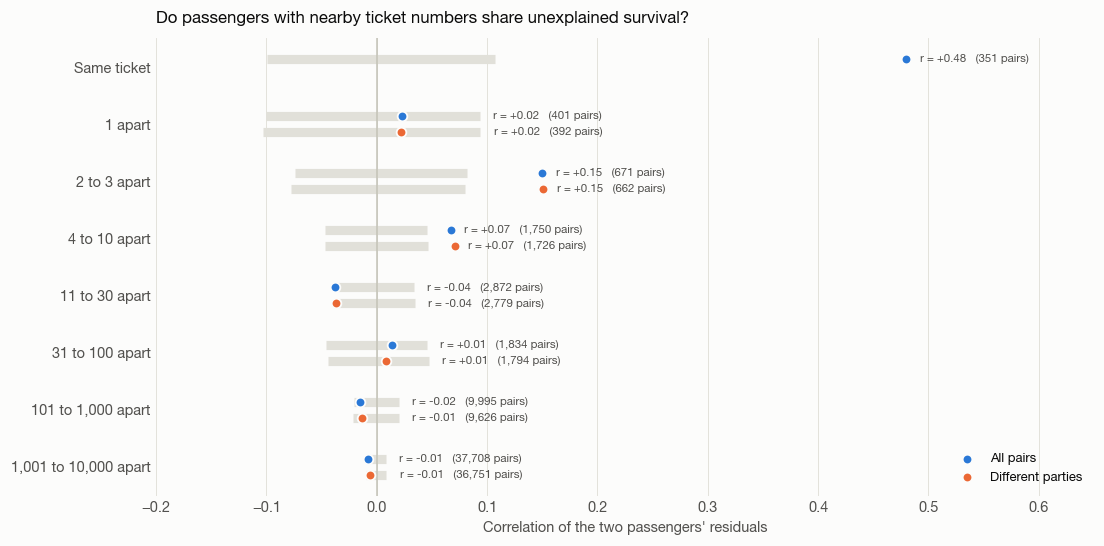

Distance,Scope,Pairs,Correlation,p
Same ticket,All pairs,351,0.480000,0.001000
"Same number, other prefix",All pairs,3,0.664000,0.161000
"Same number, other prefix",Different parties,3,0.664000,0.161000
1 apart,All pairs,401,0.023000,0.630000
1 apart,Different parties,392,0.022000,0.642000
2 to 3 apart,All pairs,671,0.150000,0.001000
2 to 3 apart,Different parties,662,0.151000,0.001000
4 to 10 apart,All pairs,1750,0.067000,0.010000
4 to 10 apart,Different parties,1726,0.071000,0.006000
11 to 30 apart,All pairs,2872,-0.037000,0.046000


In [4]:
num = tr["Num"].values
z = ((tr["Resid"] - tr["Resid"].mean()) / tr["Resid"].std()).values
I, J = np.triu_indices(len(tr), 1)
same_ticket = tr["Ticket"].values[I] == tr["Ticket"].values[J]
same_party = tr["Party"].values[I] == tr["Party"].values[J]
dist = np.abs(num[I] - num[J])
BINS = [("Same ticket", same_ticket),
        ("Same number, other prefix", ~same_ticket & (dist == 0))]
for lo, hi, lab in [(1, 1, "1 apart"), (2, 3, "2 to 3 apart"), (4, 10, "4 to 10 apart"), (11, 30, "11 to 30 apart"),
                    (31, 100, "31 to 100 apart"), (101, 1000, "101 to 1,000 apart"), (1001, 10000, "1,001 to 10,000 apart")]:
    BINS.append((lab, ~same_ticket & (dist >= lo) & (dist <= hi)))
rows = []
nullp = 1000
perm_z = np.array([RNG.permutation(z) for _ in range(nullp)])
for lab, msk in BINS:
    for scope, m2 in [("All pairs", msk), ("Different parties", msk & ~same_party)]:
        if lab == "Same ticket" and scope == "Different parties":
            continue
        ii, jj = I[m2], J[m2]
        if len(ii) == 0:
            continue
        r = np.mean(z[ii] * z[jj])
        null = (perm_z[:, ii] * perm_z[:, jj]).mean(axis=1)
        rows.append(dict(bin=lab, scope=scope, pairs=len(ii), r=r, lo=np.quantile(null, 0.025), hi=np.quantile(null, 0.975),
                         p=(np.sum(np.abs(null) >= abs(r)) + 1) / (nullp + 1)))
PR = pd.DataFrame(rows)

order = [b for b, _ in BINS if b in PR["bin"].values and b != "Same number, other prefix"]
fig, ax = plt.subplots(figsize=(11, 0.5 * len(order) + 1.4))
for i, b in enumerate(order):
    for scope, off, col in [("All pairs", -0.14, BLUE), ("Different parties", 0.14, ORANGE)]:
        r = PR[(PR["bin"] == b) & (PR["scope"] == scope)]
        if r.empty:
            continue
        r = r.iloc[0]
        ax.plot([r["lo"], r["hi"]], [i + off, i + off], color=GRID, linewidth=6, solid_capstyle="butt", zorder=2)
        ax.scatter([r["r"]], [i + off], s=40, color=col, edgecolor=SURFACE, linewidth=1.2, zorder=4,
                   label=scope if i == 1 else None)
        ax.text(max(r["r"], r["hi"]) + 0.012, i + off, f"r = {r['r']:+.2f}   ({int(r['pairs']):,} pairs)",
                va="center", fontsize=7.5, color=INK2)
ax.axvline(0, color=AXIS, linewidth=1)
ax.set_yticks(range(len(order)), order); ax.invert_yaxis()
ax.set_xlim(-0.2, 0.65)
ax.grid(axis="x", color=GRID, linewidth=0.6); ax.tick_params(length=0)
for sp in ax.spines.values():
    sp.set_visible(False)
ax.set_xlabel("Correlation of the two passengers' residuals")
ax.legend(loc="lower right", frameon=False, fontsize=8.5)
ax.set_title("Do passengers with nearby ticket numbers share unexplained survival?", loc="left", fontsize=11, pad=10)
plt.show()
t_ = PR.assign(r=PR["r"].round(3), p=PR["p"].round(3))[["bin", "scope", "pairs", "r", "p"]]
t_.columns = ["Distance", "Scope", "Pairs", "Correlation", "p"]
display(t_.style.hide(axis="index"))

The correlation is concentrated on the same ticket (0.48). Across different tickets it is 0.15 at 2 to 3 apart and 0.07 at 4 to 10 apart, outside the random range in both cases and unchanged when same-party pairs are removed. 1 apart, and everything beyond 10 apart, sits inside the random range. The 3 pairs sharing a number under different prefixes (`751`, `752`, `17474`, `2673`) are too few to read; the 751 and 752 holders are 2nd and 3rd class passengers on different prefixes, not one group.

## Which groups stand out

Each dot is one group with at least 3 train passengers, placed by its size and its mean residual. Random groups of the same size fall inside the grey funnel 95% of the time; dots outside it are labelled. With dozens of groups per panel, a few dots outside the funnel are expected by chance, so the table below adjusts for the number of groups tested (Benjamini-Hochberg q; below 0.10 is worth acting on).

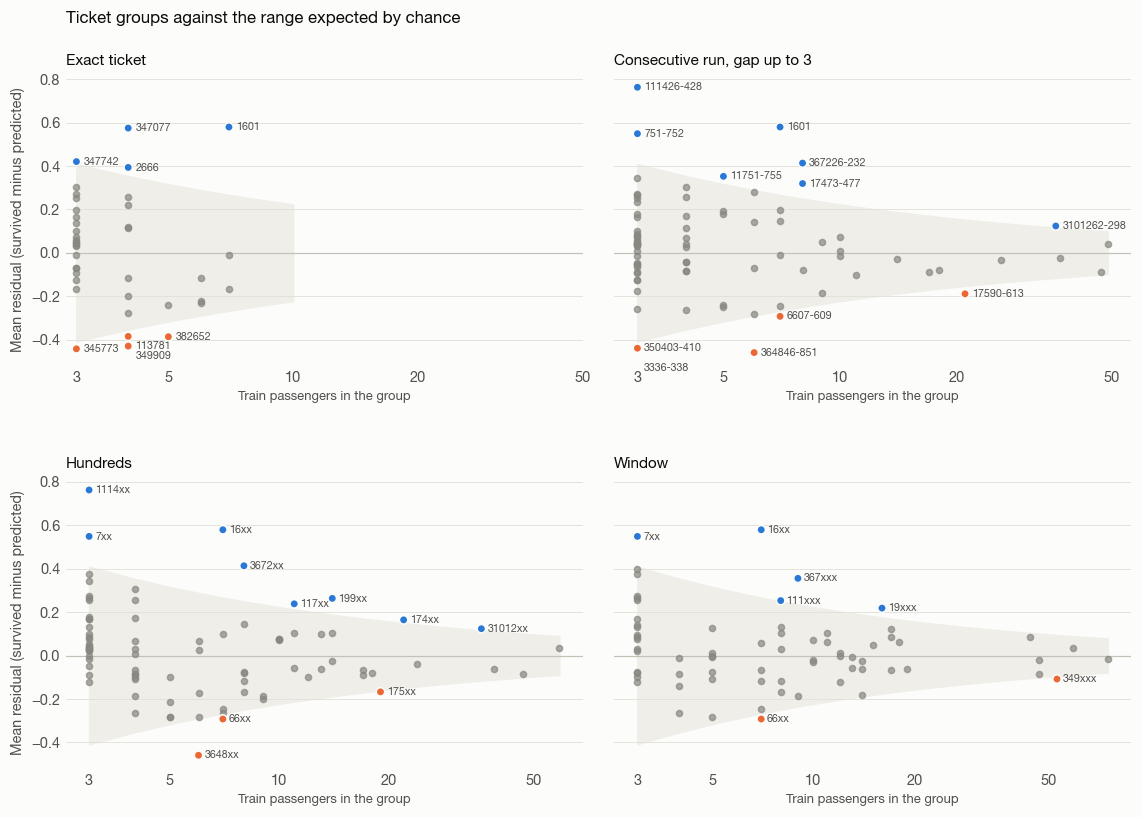

Grouping,Group,Train passengers,Parties,Class,Survived,Model expected,Mean residual,p,q
Exact ticket,1601,7,1,3,71%,14%,+0.58,0.0002,0.010
"Consecutive run, gap up to 3",1601,7,1,3,71%,14%,+0.58,0.0002,0.020
Hundreds,1114xx,3,3,1,100%,24%,+0.76,0.0005,0.021
Hundreds,16xx,7,1,3,71%,14%,+0.58,0.0002,0.021
Window,16xx,7,1,3,71%,14%,+0.58,0.0005,0.034
"Consecutive run, gap up to 3",111426-428,3,3,1,100%,24%,+0.76,0.0010,0.040
"Consecutive run, gap up to 3",367226-232,8,6,3,75%,34%,+0.41,0.0020,0.053
Exact ticket,347077,4,1,3,75%,18%,+0.57,0.0027,0.055
Hundreds,3672xx,8,6,3,75%,34%,+0.41,0.0022,0.063
"Consecutive run, gap up to 3",364846-851,6,5,3,0%,46%,-0.46,0.0032,0.065


In [5]:
def bh(p):
    p = np.asarray(p); o = np.argsort(p); q = np.empty_like(p)
    q[o] = np.minimum.accumulate((p[o] * len(p) / np.arange(1, len(p) + 1))[::-1])[::-1]
    return np.minimum(q, 1)

PANELS = ["Exact ticket", "Consecutive run, gap up to 3", "Hundreds", "Window"]
sd = tr["Resid"].std(); N = len(tr)
fig, axes = plt.subplots(2, 2, figsize=(12.5, 8.2), sharey=True, gridspec_kw={"hspace": 0.38, "wspace": 0.06})
flag = []
for ax, name in zip(axes.flat, PANELS):
    g = GROUPS[name]; g = g[g["n"] >= 3].copy()
    g["q"] = bh(g["p"].values)
    g["level"] = name
    flag.append(g)
    nn = np.arange(3, max(g["n"].max(), 10) + 1)
    band = 1.96 * sd / np.sqrt(nn) * np.sqrt((N - nn) / (N - 1))
    ax.fill_between(nn, -band, band, color="#efeee9", zorder=1)
    out = np.abs(g["mean"]) > 1.96 * sd / np.sqrt(g["n"]) * np.sqrt((N - g["n"]) / (N - 1))
    ax.scatter(g.loc[~out, "n"], g.loc[~out, "mean"], s=16, color=MUTED, alpha=0.7, zorder=3)
    ax.scatter(g.loc[out, "n"], g.loc[out, "mean"], s=30, color=[BLUE if v > 0 else ORANGE for v in g.loc[out, "mean"]],
               edgecolor=SURFACE, linewidth=1, zorder=4)
    placed = []
    for _, r in g[out].sort_values(["n", "mean"]).iterrows():
        yl = r["mean"]
        while any(pn == r["n"] and abs(yl - py) < 0.045 for pn, py in placed):
            yl += 0.045 if r["mean"] > 0 else -0.045
        placed.append((r["n"], yl))
        ax.annotate(str(r["group"]).replace(".0", ""), (r["n"], r["mean"]), xytext=(r["n"] * 1.04, yl),
                    textcoords="data", fontsize=7, color=INK2, va="center")
    ax.axhline(0, color=AXIS, linewidth=0.8)
    ax.set_xscale("log"); ax.set_xticks([3, 5, 10, 20, 50], ["3", "5", "10", "20", "50"]); ax.minorticks_off()
    ax.grid(axis="y", color=GRID, linewidth=0.6); ax.tick_params(length=0)
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.set_title(name, loc="left", fontsize=10, pad=6)
    ax.set_xlabel("Train passengers in the group", fontsize=8.5)
for ax in axes[:, 0]:
    ax.set_ylabel("Mean residual (survived minus predicted)")
fig.suptitle("Ticket groups against the range expected by chance", x=0.125, ha="left", fontsize=11, y=0.95)
plt.show()

F = pd.concat(flag)
F = F[F["q"] < 0.25].sort_values("q")
detail = []
for _, r in F.iterrows():
    col = dict(LEVELS)[r["level"]]
    m = tr[tr[col].astype(str) == str(r["group"])]
    detail.append({"Grouping": r["level"], "Group": str(r["group"]).replace(".0", ""), "Train passengers": int(r["n"]),
                   "Parties": m["Party"].nunique(), "Class": "/".join(sorted(m["Pclass"].astype(str).unique())),
                   "Survived": f"{m['Survived'].mean():.0%}", "Model expected": f"{m['Pred'].mean():.0%}",
                   "Mean residual": f"{r['mean']:+.2f}", "p": f"{r['p']:.4f}", "q": f"{r['q']:.3f}"})
D = pd.DataFrame(detail)
if len(D):
    display(D.style.hide(axis="index"))
else:
    display(Markdown("No group has q below 0.25."))

Most groups fall inside the funnel. The outliers that survive the adjustment for multiple testing are a handful of small groups: single-party tickets (1601, 347077) and a few runs that span several parties (111426 to 111428, 367226 to 367232, 364846 to 364851). The large windows sit close to zero, apart from 349xxx (53 train passengers, mean residual -0.11) and 175xx in the hundreds, both just outside the funnel and not significant after adjustment.